In [2]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt 
from sklearn.model_selection import train_test_split as tts 
from sklearn.datasets import load_diabetes
from sklearn.metrics import mean_squared_error, r2_score
from sklearn.linear_model import Ridge,Lasso, LinearRegression
from sklearn.preprocessing import StandardScaler

In [8]:
data = load_diabetes(as_frame=True)
df = data.frame

display(df.shape)
display(df.head())

(442, 11)

,age,sex,bmi,bp,s1,s2,s3,s4,s5,s6,target
0,0.038076,0.050680,0.061696,0.021872,-0.044223,-0.034821,-0.043401,-0.002592,0.019907,-0.017646,151.0
1,-0.001882,-0.044642,-0.051474,-0.026328,-0.008449,-0.019163,0.074412,-0.039493,-0.068332,-0.092204,75.0
2,0.085299,0.050680,0.044451,-0.005670,-0.045599,-0.034194,-0.032356,-0.002592,0.002861,-0.025930,141.0
3,-0.089063,-0.044642,-0.011595,-0.036656,0.012191,0.024991,-0.036038,0.034309,0.022688,-0.009362,206.0
4,0.005383,-0.044642,-0.036385,0.021872,0.003935,0.015596,0.008142,-0.002592,-0.031988,-0.046641,135.0


In [10]:
X = df.drop("target",axis=1)
y = df["target"]

In [11]:
xtr, xt, ytr, yt = tts(X, y, test_size=0.2, random_state=42)

In [12]:
sc = StandardScaler()
xtr = sc.fit_transform(xtr)
xt = sc.transform(xt)

In [24]:
models = {
    "Linear": LinearRegression(),
    "Ridge": Ridge(alpha=1),
    "Lasso": Lasso(alpha=0.1)
}

for name, model in models.items():
    model.fit(xtr, ytr)

In [25]:
res = []
for name, model in models.items():
    pred = model.predict(xt)
    mse = mean_squared_error(yt, pred)
    rmse = np.sqrt(mse)
    r2 = r2_score(yt, pred)

    # Pass the actual variables instead of string literals
    res.append([name, mse, rmse, r2])

result = pd.DataFrame(
    res,
    columns = ["Model", "MSE", "RMSE", "r2"]
)


In [26]:
# Compare COefficients
coef = pd.DataFrame(
    {
        name: model.coef_ for name, model in models.items()
    },
    index=X.columns
)

print(coef.round(2))

     Linear  Ridge  Lasso
age    1.75   1.81   1.73
sex  -11.51 -11.45 -11.32
bmi   25.61  25.73  25.82
bp    16.83  16.73  16.64
s1   -44.45 -34.67 -29.36
s2    24.64  17.05  13.28
s3     7.68   3.37   0.55
s4    13.14  11.76  10.24
s5    35.16  31.38  29.63
s6     2.35   2.46   2.39


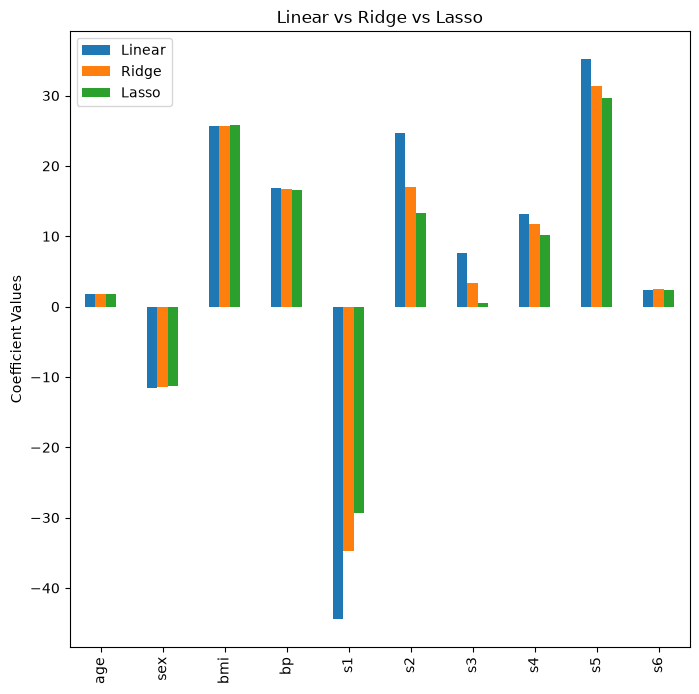

In [27]:
coef.plot(kind="bar", figsize=(8,8))
plt.title("Linear vs Ridge vs Lasso")
plt.ylabel("Coefficient Values")
plt.show()

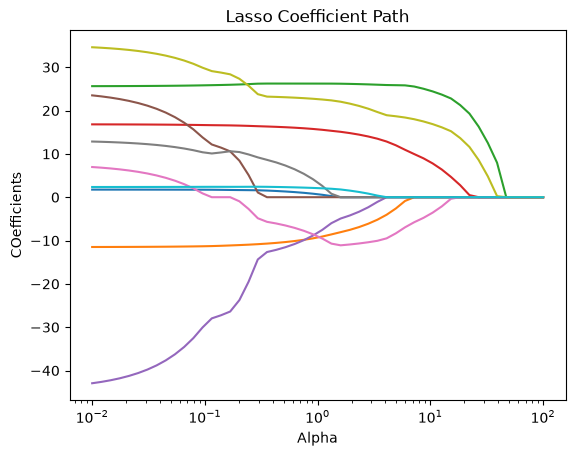

In [29]:
# Lasso Coefficient Path
alphas = np.logspace(-2,2,50)
path = []

for a in alphas:
    model = Lasso(alpha=a, max_iter=1000)
    model.fit(xtr,ytr)
    path.append(model.coef_)

plt.plot(alphas,path)
plt.xscale("log")
plt.xlabel("Alpha")
plt.ylabel("COefficients")
plt.title("Lasso Coefficient Path")
plt.show()